# 03 · Evaluation, calibration and the leakage comparison

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Rishabh-bgp/brain-tumor-mri-classification/blob/main/notebooks/03_evaluation_and_calibration.ipynb)

Turns saved logits into the single prediction file (`results/predictions/*_test_predictions.csv`), fits temperature scaling and the *uncertain* threshold on validation, and derives every reported metric, table, figure and the web demo's statistics from that file.

*Rishabh Aryan · M.Tech (AI & Data Science), IIIT Bhagalpur. Research and education code, not a medical device.*

In [1]:
# --- Setup: works locally (repo checkout) and on Google Colab ---
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("brain-tumor-mri-classification"):
        subprocess.run(["git", "clone", "-q", "https://github.com/Rishabh-bgp/brain-tumor-mri-classification.git"], check=True)
    os.chdir("brain-tumor-mri-classification")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "kagglehub", "imagehash", "captum",
                    "onnx", "onnxruntime", "scikit-image"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
print("working directory:", os.getcwd())

working directory: /workspace/brain-tumor-mri/repo


In [2]:
import torch
print("PyTorch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU (Colab: Runtime > Change runtime type > GPU for faster training)")

PyTorch 2.15.0+cpu | CUDA available: False
Running on CPU (Colab: Runtime > Change runtime type > GPU for faster training)


In [3]:
subprocess.run([sys.executable, "scripts/make_predictions.py"], check=True)
subprocess.run([sys.executable, "scripts/make_report.py"], check=True)
import json, pandas as pd
cal = json.load(open("results/predictions/calibration.json"))
print(json.dumps(cal, indent=1))

clean {
 "temperature": 1.9089141465158759,
 "val_ece_raw": 0.01102967713134229,
 "val_ece_calibrated": 0.00792585021716924,
 "uncertainty": {
  "conf_threshold": 0.69,
  "target_val_accuracy": 0.99,
  "val_retained_accuracy": 0.9908952959028832,
  "val_coverage": 0.9865269461077845,
  "rule": "smallest t in [0.50,0.99] (step 0.01) with val accuracy >= 0.99 on predictions with calibrated confidence >= t"
 },
 "val_accuracy": 0.9865269461077845
}
naive {
 "temperature": 1.7346503503040023,
 "val_ece_raw": 0.010562407458376766,
 "val_ece_calibrated": 0.016256220229184975,
 "uncertainty": {
  "conf_threshold": 0.5,
  "target_val_accuracy": 0.99,
  "val_retained_accuracy": 0.9904761904761905,
  "val_coverage": 1.0,
  "rule": "smallest t in [0.50,0.99] (step 0.01) with val accuracy >= 0.99 on predictions with calibrated confidence >= t"
 },
 "val_accuracy": 0.9904761904761905
}


{
 "clean": {
  "full_test": [
   0.91875,
   0.9185037573113346,
   1600
  ],
  "dedup_test": [
   0.9187779433681073,
   0.9115909251325687,
   1342
  ],
  "test_with_strict_train_dup": [
   0.8798185941043084,
   0.563714312513544,
   441
  ],
  "test_without_linked_train_dup": [
   0.9247422680412372,
   0.8421230107139818,
   970
  ]
 },
 "naive": {
  "full_test": [
   0.96125,
   0.9605436442969923,
   1600
  ],
  "dedup_test": [
   0.9590163934426229,
   0.958544119847771,
   1342
  ],
  "test_with_strict_train_dup": [
   0.9954648526077098,
   0.955188679245283,
   441
  ],
  "test_without_linked_train_dup": [
   0.9402061855670103,
   0.8942194381075547,
   970
  ]
 }
}
{
 "clean|glioma|dup": {
  "n": 9,
  "correct": 7,
  "accuracy": 0.7777777777777778
 },
 "naive|glioma|dup": {
  "n": 9,
  "correct": 7,
  "accuracy": 0.7777777777777778
 },
 "clean|glioma|nodup": {
  "n": 391,
  "correct": 330,
  "accuracy": 0.8439897698209718
 },
 "naive|glioma|nodup": {
  "n": 391,
  "correc

{
 "clean": {
  "temperature": 1.9089141465158759,
  "val_ece_raw": 0.01102967713134229,
  "val_ece_calibrated": 0.00792585021716924,
  "uncertainty": {
   "conf_threshold": 0.69,
   "target_val_accuracy": 0.99,
   "val_retained_accuracy": 0.9908952959028832,
   "val_coverage": 0.9865269461077845,
   "rule": "smallest t in [0.50,0.99] (step 0.01) with val accuracy >= 0.99 on predictions with calibrated confidence >= t"
  },
  "val_accuracy": 0.9865269461077845
 },
 "naive": {
  "temperature": 1.7346503503040023,
  "val_ece_raw": 0.010562407458376766,
  "val_ece_calibrated": 0.016256220229184975,
  "uncertainty": {
   "conf_threshold": 0.5,
   "target_val_accuracy": 0.99,
   "val_retained_accuracy": 0.9904761904761905,
   "val_coverage": 1.0,
   "rule": "smallest t in [0.50,0.99] (step 0.01) with val accuracy >= 0.99 on predictions with calibrated confidence >= t"
  },
  "val_accuracy": 0.9904761904761905
 }
}


In [4]:
pred = pd.read_csv("results/predictions/clean_test_predictions.csv")
display(pred.head())
m = json.load(open("results/metrics.json"))
rows = []
for run in ("clean", "naive"):
    for k, v in m[run].items():
        rows.append({"model": run, "subset": k, "n": v["n"], "accuracy": v["accuracy"], "acc 95% CI": v["accuracy_ci95"],
                     "macro_F1": v["macro_f1"], "ROC-AUC": v.get("roc_auc_macro_ovr"), "ECE": v["ece_calibrated"]})
display(pd.DataFrame(rows).round(4))

,relpath,true,pred,p_glioma,p_meningioma,p_notumor,p_pituitary,raw_p_glioma,raw_p_meningioma,raw_p_notumor,raw_p_pituitary,confidence,norm_entropy,uncertain,test_has_train_dup_strict,test_has_train_dup,test_dedup_rep
0,Testing/glioma/Te-gl_1.jpg,glioma,glioma,0.999376,0.000091,0.000082,0.000451,1.000000,0.000000,0.000000,0.000000,0.999376,0.004121,False,False,False,True
1,Testing/glioma/Te-gl_10.jpg,glioma,glioma,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,False,False,True,True
2,Testing/glioma/Te-gl_100.jpg,glioma,glioma,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,False,False,False,True
3,Testing/glioma/Te-gl_101.jpg,glioma,glioma,0.923805,0.075381,0.000129,0.000685,0.991703,0.008296,0.000000,0.000001,0.923805,0.197821,False,False,False,True
4,Testing/glioma/Te-gl_102.jpg,glioma,notumor,0.053991,0.000481,0.942674,0.002854,0.004238,0.000001,0.995746,0.000015,0.942674,0.168537,False,False,False,True


,model,subset,n,accuracy,acc 95% CI,macro_F1,ROC-AUC,ECE
0,clean,full_test,1600,0.9188,"[0.904984, 0.931875]",0.9185,0.9867,0.0523
1,clean,dedup_test,1342,0.9188,"[0.903875, 0.932191]",0.9116,0.9857,0.0515
2,clean,test_with_strict_train_dup,441,0.8798,"[0.85034, 0.911565]",0.5637,NaN,0.0918
3,clean,test_without_linked_train_dup,970,0.9247,"[0.908247, 0.940206]",0.8421,0.9876,0.0456
4,naive,full_test,1600,0.9612,"[0.951234, 0.970016]",0.9605,0.9908,0.0222
5,naive,dedup_test,1342,0.9590,"[0.947839, 0.968722]",0.9585,0.9895,0.0234
6,naive,test_with_strict_train_dup,441,0.9955,"[0.988662, 1.0]",0.9552,NaN,0.0053
7,naive,test_without_linked_train_dup,970,0.9402,"[0.925773, 0.954639]",0.8942,0.9873,0.0350


In [5]:
full = m["clean"]["full_test"]
display(pd.DataFrame(full["per_class"]).T.round(4))
print("confusion matrix (rows = true, cols = predicted; glioma, meningioma, notumor, pituitary):")
print(pd.DataFrame(full["confusion_matrix"], index=["glioma", "meningioma", "notumor", "pituitary"], columns=["glioma", "meningioma", "notumor", "pituitary"]))
print("uncertain rate:", round(full["uncertain_rate"], 4), "| accuracy confident:", full["accuracy_confident"], "| accuracy uncertain:", full["accuracy_uncertain"])

,precision,recall,f1,support
glioma,0.9684,0.8425,0.9011,400.0
meningioma,0.9412,0.8400,0.8877,400.0
notumor,0.8160,0.9975,0.8976,400.0
pituitary,0.9803,0.9950,0.9876,400.0


confusion matrix (rows = true, cols = predicted; glioma, meningioma, notumor, pituitary):
            glioma  meningioma  notumor  pituitary
glioma         337          21       42          0
meningioma       8         336       48          8
notumor          1           0      399          0
pituitary        2           0        0        398
uncertain rate: 0.035 | accuracy confident: 0.9378238341968912 | accuracy uncertain: 0.39285714285714285


### Leakage by class: Testing images with vs without a strict near-duplicate in the original Training folder

In [6]:
lb = pd.DataFrame(m["leakage_by_class"]).T
lb.index = pd.MultiIndex.from_tuples([tuple(i.split("|")) for i in lb.index], names=["model", "class", "subset"])
display(lb.unstack(["model", "subset"]))
subprocess.run([sys.executable, "scripts/audit_augmented.py"], check=True)  # files named *-aug-* (augmented meningiomas)

n                      correct                       accuracy  \
model       clean  naive  clean  naive   clean  naive  clean  naive     clean   
subset        dup    dup  nodup  nodup     dup    dup  nodup  nodup       dup   
class                                                                           
glioma        9.0    9.0  391.0  391.0     7.0    7.0  330.0  339.0  0.777778   
meningioma  105.0  105.0  295.0  295.0    55.0  105.0  281.0  288.0  0.523810   
notumor     327.0  327.0   73.0   73.0   326.0  327.0   73.0   73.0  0.996942   
pituitary     0.0    0.0  400.0  400.0     0.0    0.0  398.0  399.0       NaN   

                                          
model          naive     clean     naive  
subset           dup     nodup     nodup  
class                                     
glioma      0.777778  0.843990  0.867008  
meningioma  1.000000  0.952542  0.976271  
notumor     1.000000  1.000000  1.000000  
pituitary        NaN  0.995000  0.997500

{
  "n_aug_training": 100,
  "n_aug_testing": 103,
  "linked_any": 26,
  "linked_non_identity": 10,
  "clean_acc_test_aug_meningioma": 0.9805825242718447,
  "clean_acc_test_other_meningioma": 0.7912457912457912,
  "clean_n_aug": 103,
  "clean_n_other": 297,
  "clean_nodup_aug_correct": 100,
  "clean_nodup_aug_n": 102,
  "clean_nodup_other_correct": 181,
  "clean_nodup_other_n": 193,
  "naive_acc_test_aug_meningioma": 0.970873786407767,
  "naive_acc_test_other_meningioma": 0.9865319865319865,
  "naive_n_aug": 103,
  "naive_n_other": 297,
  "naive_nodup_aug_correct": 99,
  "naive_nodup_aug_n": 102,
  "naive_nodup_other_correct": 189,
  "naive_nodup_other_n": 193
}


CompletedProcess(args=['/workspace/brain-tumor-mri/.venv/bin/python3', 'scripts/audit_augmented.py'], returncode=0)

### Robustness check: a looser link rule (no retraining)
How many more Testing images would a rule that also links Hamming 7–10 with correlation ≥ 0.95 tie to our train/validation images, and what is the accuracy without them?

In [7]:
print(json.dumps(m["sensitivity_looser_rule"], indent=1))
sd = m["clean"]["test_with_strict_train_dup"]
print(sd["macro_f1_note"]); print("macro-F1 over present classes", sd["present_classes"], "=", round(sd["macro_f1_present_classes"], 4))

{
 "rule": "extra links: Hamming 7-10 and thumbnail correlation >= 0.95 (not already linked)",
 "extra_pairs": 644,
 "extra_test_images_linked_to_train_val": 84,
 "extra_by_class": {
  "pituitary": 58,
  "glioma": 11,
  "notumor": 10,
  "meningioma": 5
 },
 "clean_acc_full": 0.91875,
 "clean_acc_excluding_extra": 0.9142480211081794,
 "n_excluding_extra": 1516,
 "clean_acc_on_extra": 1.0
}
macro_f1 averages over all four classes; pituitary has no images in this subset (support 0) but receives predictions, so its F1 is counted as 0. macro_f1_present_classes averages only the classes present.
macro-F1 over present classes ['glioma', 'meningioma', 'notumor'] = 0.7516


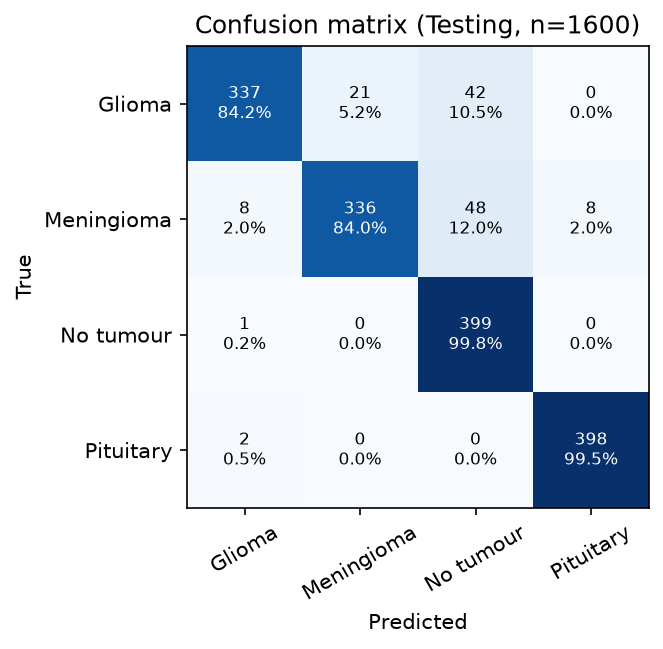

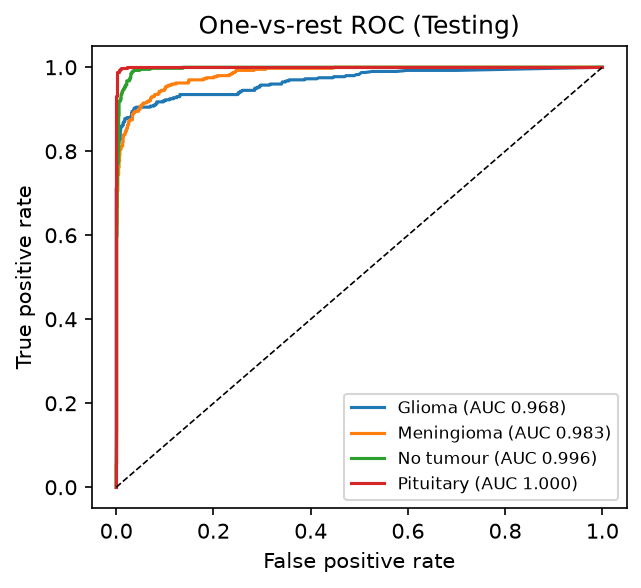

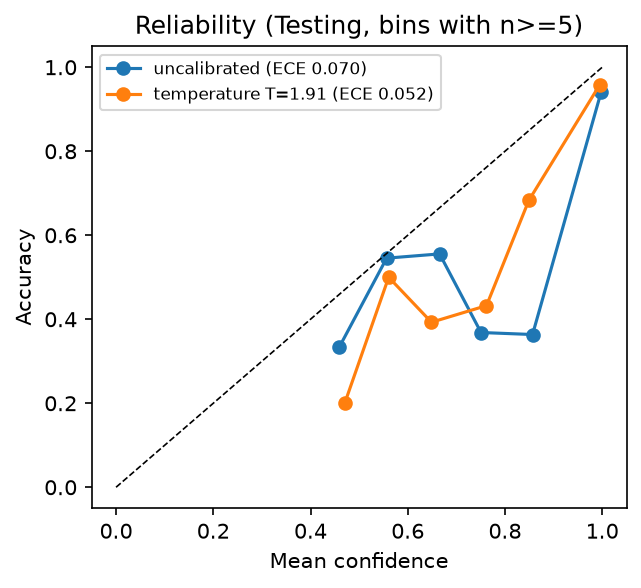

In [8]:
from IPython.display import Image, display
for f in ("confusion_matrix", "roc_curves", "reliability"):
    display(Image(f"results/figures/{f}.png", width=480))